In [52]:
import os
import time
import glob
import random
from dataclasses import dataclass, field
from typing import List, Optional, Dict, Any

import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

In [54]:
class ImageSampler:
    VALID_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

    def __init__(self, image_dir: str, seed: int):
        self.image_dir = image_dir
        self.rng = random.Random(seed)
        self.image_paths = self._collect_images()
        if not self.image_paths:
            raise FileNotFoundError(f"No images found in {image_dir}")

    def _collect_images(self) -> List[str]:
        paths = glob.glob(os.path.join(self.image_dir, '**', '*'), recursive=True)
        return [p for p in paths if p.lower().endswith(self.VALID_EXT)]

    def sample(self, n: int) -> List[str]:
        n = min(n, len(self.image_paths))
        return self.rng.sample(self.image_paths, n)


In [55]:
class ImageAugmentor:
    """Applies a random subset of augmentations. Deterministic given a seed."""

    def __init__(self, seed: int):
        self.rng = random.Random(seed)
        self.np_rng = np.random.default_rng(seed)

    def augment(self, image: np.ndarray) -> np.ndarray:
        img = image.copy()
        ops = [self._flip, self._brightness_contrast, self._rotate,
               self._gaussian_noise, self._blur]
        # apply a random 2-3 of the available ops
        chosen = self.rng.sample(ops, k=self.rng.randint(2, 3))
        for op in chosen:
            img = op(img)
        return img

    def _flip(self, img):
        return cv2.flip(img, 1) if self.rng.random() > 0.5 else img

    def _brightness_contrast(self, img):
        alpha = self.rng.uniform(0.8, 1.2)   # contrast
        beta = self.rng.uniform(-25, 25)     # brightness
        return cv2.convertScaleAbs(img, alpha=alpha, beta=beta)

    def _rotate(self, img):
        angle = self.rng.uniform(-15, 15)
        h, w = img.shape[:2]
        m = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
        return cv2.warpAffine(img, m, (w, h), borderMode=cv2.BORDER_REFLECT)

    def _gaussian_noise(self, img):
        noise = self.np_rng.normal(0, 8, img.shape).astype(np.int16)
        return np.clip(img.astype(np.int16) + noise, 0, 255).astype(np.uint8)

    def _blur(self, img):
        k = self.rng.choice([3, 5])
        return cv2.GaussianBlur(img, (k, k), 0)

In [56]:
class YOLOEvaluator:
    def __init__(self, model_path: str):
        self.model = YOLO(model_path)

    def predict(self, image: np.ndarray, conf: float, iou: float):
        return self.model.predict(image, conf=conf, iou=iou, verbose=False)[0]

    def run_official_validation(self, data_yaml: str):
        """Runs ultralytics' built-in val() for mAP/precision/recall, if a data.yaml is provided."""
        return self.model.val(data=data_yaml, verbose=False)


In [57]:
class ResultVisualizer:
    @staticmethod
    def plot_confidence_distribution(records: List[Dict[str, Any]]):
        all_confs = np.concatenate([r['confidences'] for r in records if len(r['confidences'])]) \
            if any(len(r['confidences']) for r in records) else np.array([])
        plt.figure(figsize=(6, 4))
        if len(all_confs):
            plt.hist(all_confs, bins=20, color='steelblue', edgecolor='black')
        plt.title("Detection Confidence Distribution")
        plt.xlabel("Confidence")
        plt.ylabel("Count")
        plt.tight_layout()
        plt.show()

    @staticmethod
    def plot_class_distribution(records: List[Dict[str, Any]], class_names: Dict[int, str]):
        counts = {}
        for r in records:
            for c in r['classes']:
                name = class_names.get(int(c), str(int(c)))
                counts[name] = counts.get(name, 0) + 1
        plt.figure(figsize=(6, 4))
        if counts:
            plt.bar(counts.keys(), counts.values(), color='darkorange')
            plt.xticks(rotation=45, ha='right')
        plt.title("Detections per Class")
        plt.ylabel("Count")
        plt.tight_layout()
        plt.show()

    @staticmethod
    def plot_inference_times(records: List[Dict[str, Any]]):
        times = [r['inference_time'] * 1000 for r in records]  # ms
        plt.figure(figsize=(6, 4))
        plt.plot(times, marker='o', color='seagreen')
        plt.title("Inference Time per Image")
        plt.xlabel("Sample index")
        plt.ylabel("Time (ms)")
        plt.tight_layout()
        plt.show()

    @staticmethod
    def show_sample_predictions(records: List[Dict[str, Any]], n: int):
        n = min(n, len(records))
        if n == 0:
            return
        cols = min(3, n)
        rows = (n + cols - 1) // cols
        fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows))
        axes = np.array(axes).reshape(-1)
        for ax, rec in zip(axes, records[:n]):
            ax.imshow(rec['annotated_image'])
            ax.set_title(f"{os.path.basename(rec['path'])}\n"
                         f"{rec['num_detections']} detections", fontsize=9)
            ax.axis('off')
        for ax in axes[n:]:
            ax.axis('off')
        plt.tight_layout()
        plt.show()



In [74]:
class UnderwaterAugmentor:
    """
    Applies exactly one randomly-chosen underwater-style augmentation per call.
    Operates on BGR images (OpenCV's default), consistent with the rest of the pipeline.
    """

    def __init__(self, seed: int):
        self.rng = random.Random(seed)
        self.np_rng = np.random.default_rng(seed)

    def augment(self, image: np.ndarray) -> np.ndarray:
        ops = [
            self._color_cast,
            self._sun_flare,
            self._glare_spots,
            self._turbidity_haze,
            self._vignette,
            self._low_visibility_blur,
        ]
        chosen_op = self.rng.choice(ops)
        return chosen_op(image.copy())

    # ------------------------------------------------------------------
    # Simulates the blue/green tint caused by water absorbing red light
    # first as depth increases.
    # ------------------------------------------------------------------
    def _color_cast(self, img: np.ndarray) -> np.ndarray:
        b, g, r = cv2.split(img.astype(np.float32))

        red_attenuation = self.rng.uniform(0.4, 0.7)     # red fades most
        green_boost = self.rng.uniform(1.0, 1.15)
        blue_boost = self.rng.uniform(1.05, 1.25)

        r *= red_attenuation
        g *= green_boost
        b *= blue_boost

        return cv2.merge([
            np.clip(b, 0, 255),
            np.clip(g, 0, 255),
            np.clip(r, 0, 255),
        ]).astype(np.uint8)

    # ------------------------------------------------------------------
    # Simulates sunlight rays / beams entering from the surface.
    # ------------------------------------------------------------------
    def _sun_flare(self, img: np.ndarray) -> np.ndarray:
        h, w = img.shape[:2]
        flare_layer = np.zeros_like(img, dtype=np.float32)

        # Flare source near the top of the frame (surface light direction)
        src_x = self.rng.randint(int(w * 0.2), int(w * 0.8))
        src_y = self.rng.randint(0, int(h * 0.25))

        num_rays = self.rng.randint(4, 8)
        for _ in range(num_rays):
            angle = self.rng.uniform(0, 2 * np.pi)
            length = self.rng.randint(int(h * 0.5), h)
            end_x = int(src_x + length * np.cos(angle))
            end_y = int(src_y + length * np.sin(angle))
            thickness = self.rng.randint(2, 6)
            cv2.line(flare_layer, (src_x, src_y), (end_x, end_y),
                      (255, 255, 220), thickness, lineType=cv2.LINE_AA)

        flare_layer = cv2.GaussianBlur(flare_layer, (25, 25), 0)

        # Bright core at the source
        cv2.circle(flare_layer, (src_x, src_y), self.rng.randint(15, 40),
                   (255, 255, 230), -1, lineType=cv2.LINE_AA)
        flare_layer = cv2.GaussianBlur(flare_layer, (31, 31), 0)

        alpha = self.rng.uniform(0.35, 0.6)
        blended = img.astype(np.float32) + flare_layer * alpha
        return np.clip(blended, 0, 255).astype(np.uint8)

    # ------------------------------------------------------------------
    # Simulates specular glare/reflections (metal, glass, bubbles).
    # ------------------------------------------------------------------
    def _glare_spots(self, img: np.ndarray) -> np.ndarray:
        h, w = img.shape[:2]
        overlay = img.astype(np.float32)

        blob_count = self.rng.randint(2, 5)
        for _ in range(blob_count):
            cx, cy = self.rng.randint(0, w - 1), self.rng.randint(0, h - 1)
            axis_x = self.rng.randint(max(2, w // 40), max(4, w // 15))
            axis_y = self.rng.randint(max(2, h // 40), max(4, h // 15))
            glare_layer = np.zeros_like(img, dtype=np.float32)
            cv2.ellipse(glare_layer, (cx, cy), (axis_x, axis_y), 0, 0, 360,
                       (255, 255, 255), -1)
            glare_layer = cv2.GaussianBlur(glare_layer, (21, 21), 0)
            overlay += glare_layer * self.rng.uniform(0.3, 0.55)

        return np.clip(overlay, 0, 255).astype(np.uint8)

    # ------------------------------------------------------------------
    # Simulates murky/turbid water — reduced contrast, hazy/whitish veil.
    # ------------------------------------------------------------------
    def _turbidity_haze(self, img: np.ndarray) -> np.ndarray:
        h, w = img.shape[:2]
        haze_color = np.array([
            self.rng.uniform(90, 130),   # B
            self.rng.uniform(110, 150),  # G
            self.rng.uniform(70, 100),   # R
        ], dtype=np.float32)

        haze_layer = np.full((h, w, 3), haze_color, dtype=np.float32)
        alpha = self.rng.uniform(0.25, 0.45)   # haze strength

        blended = img.astype(np.float32) * (1 - alpha) + haze_layer * alpha
        return np.clip(blended, 0, 255).astype(np.uint8)

    # ------------------------------------------------------------------
    # Simulates light falloff at frame edges (common with wide-angle
    # underwater housings).
    # ------------------------------------------------------------------
    def _vignette(self, img: np.ndarray) -> np.ndarray:
        h, w = img.shape[:2]
        kernel_x = cv2.getGaussianKernel(w, w * self.rng.uniform(0.5, 0.8))
        kernel_y = cv2.getGaussianKernel(h, h * self.rng.uniform(0.5, 0.8))
        mask = kernel_y * kernel_x.T
        mask = mask / mask.max()

        strength = self.rng.uniform(0.5, 0.8)
        mask = strength + (1 - strength) * mask   # keep center brighter

        vignetted = img.astype(np.float32) * mask[..., np.newaxis]
        return np.clip(vignetted, 0, 255).astype(np.uint8)

    # ------------------------------------------------------------------
    # Simulates reduced visibility from suspended particles / distance.
    # ------------------------------------------------------------------
    def _low_visibility_blur(self, img: np.ndarray) -> np.ndarray:
        k = self.rng.choice([5, 7, 9])
        blurred = cv2.GaussianBlur(img, (k, k), 0)
        # slightly desaturate to mimic light scattering
        hsv = cv2.cvtColor(blurred, cv2.COLOR_BGR2HSV).astype(np.float32)
        hsv[..., 1] *= self.rng.uniform(0.6, 0.85)
        hsv = np.clip(hsv, 0, 255).astype(np.uint8)
        return cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

In [58]:
def _summarize(records: List[Dict[str, Any]]) -> Dict[str, Any]:
    all_confs = np.concatenate([r['confidences'] for r in records if len(r['confidences'])]) \
        if any(len(r['confidences']) for r in records) else np.array([])
    times = [r['inference_time'] for r in records]
    return {
        'num_images_tested': len(records),
        'total_detections': int(sum(r['num_detections'] for r in records)),
        'avg_detections_per_image': float(np.mean([r['num_detections'] for r in records])),
        'avg_confidence': float(np.mean(all_confs)) if len(all_confs) else None,
        'avg_inference_time_ms': float(np.mean(times) * 1000),
        'fps_estimate': float(1 / np.mean(times)) if np.mean(times) > 0 else None,
    }
    

def _print_summary(summary: Dict[str, Any], seed: int, augmented: bool):
    print("=" * 50)
    print("YOLO TEST PIPELINE SUMMARY")
    print("=" * 50)
    print(f"Seed:                  {seed}")
    print(f"Augmentation applied:  {augmented}")
    for k, v in summary.items():
        print(f"{k:24}: {v}")
    print("=" * 50)

In [75]:
def run_yolo_test_pipeline(
    model_path: str,
    image_dir: str,
    num_samples: int = 12,
    augment: bool = False,
    seed: Optional[int] = None,
    conf_threshold: float = 0.25,
    iou_threshold: float = 0.45,
    data_yaml: Optional[str] = None,
    show_samples: int = 6,
) -> Dict[str, Any]:
    """
    Runs a randomized end-to-end test of a YOLOv11 model: samples images,
    optionally augments them, runs inference, prints/plots metrics, and
    displays sample predictions.

    Returns a dict with 'records', 'summary', 'val_metrics', and 'seed'
    so you can inspect anything further in the notebook.
    """
    seed = seed if seed is not None else random.randint(0, 999_999)

    sampler = ImageSampler(image_dir, seed=seed)
    sampled_paths = sampler.sample(num_samples)

    augmentor = UnderwaterAugmentor(seed=seed) if augment else None
    evaluator = YOLOEvaluator(model_path)

    records = []
    for path in sampled_paths:
        img = cv2.imread(path)
        if augmentor:
            img = augmentor.augment(img)

        t0 = time.time()
        result = evaluator.predict(img, conf_threshold, iou_threshold)
        dt = time.time() - t0

        annotated = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)
        confs = result.boxes.conf.cpu().numpy() if result.boxes is not None else np.array([])
        classes = result.boxes.cls.cpu().numpy() if result.boxes is not None else np.array([])

        records.append({
            'path': path,
            'annotated_image': annotated,
            'num_detections': len(confs),
            'confidences': confs,
            'classes': classes,
            'inference_time': dt,
        })

    val_metrics = evaluator.run_official_validation(data_yaml) if data_yaml else None

    viz = ResultVisualizer()
    viz.plot_confidence_distribution(records)
    viz.plot_class_distribution(records, evaluator.model.names)
    viz.plot_inference_times(records)
    viz.show_sample_predictions(records, n=show_samples)

    summary = _summarize(records)
    _print_summary(summary, seed, augment)

    return {
        'records': records,
        'summary': summary,
        'val_metrics': val_metrics,
        'seed': seed,
    }

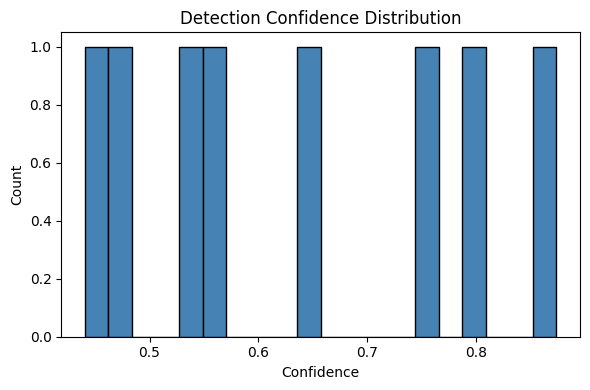

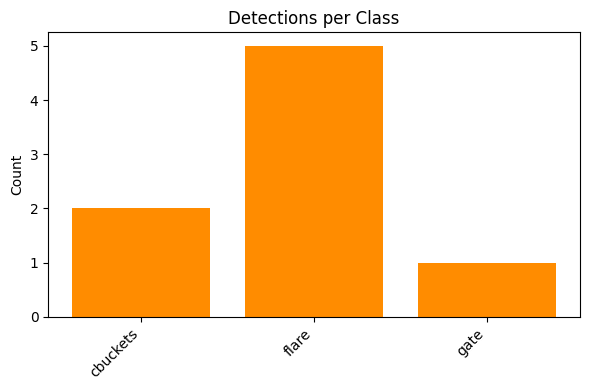

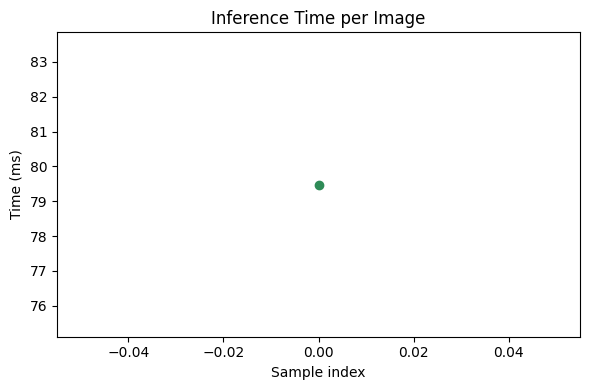

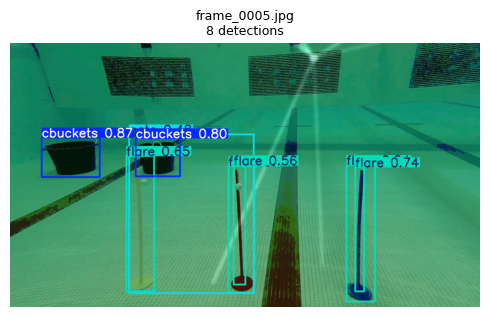

YOLO TEST PIPELINE SUMMARY
Seed:                  818746
Augmentation applied:  True
num_images_tested       : 1
total_detections        : 8
avg_detections_per_image: 8.0
avg_confidence          : 0.6357120275497437
avg_inference_time_ms   : 79.47993278503418
fps_estimate            : 12.581792220492376


In [84]:
results = run_yolo_test_pipeline(
    model_path="../cv_models/all_combined_11s/all_combined_11s_best.pt",
    image_dir="./test_img",
    num_samples=15,
    augment=True,          # flip to False to test on raw images
    seed=None,              # None = randomized every call; pass an int to reproduce a run
    conf_threshold=0.25,
)

# everything is accessible afterward:
results['summary']
results['records'][0]['confidences']
results['val_metrics']